# Calculate the conductivity using FFT method

sigma values at neg0: [np.float64(9361869.455787415), np.float64(9566981.417525966), np.float64(10516769.123248618)]
sigma values at neg1: [np.float64(5520505.857143636), np.float64(7303152.573330326), np.float64(9204513.744374271)]
sigma values at neg2: [np.float64(6400438.804677692), np.float64(9848910.893301412), np.float64(8112000.368059813)]
sigma values at pos1: [np.float64(13215235.59787944), np.float64(7810381.189991178), np.float64(11367122.340523515)]
sigma values at pos2: [np.float64(8266355.477957892), np.float64(10584399.135378527), np.float64(8704611.893937502)]
sigma values at pos5: [np.float64(9635521.257159997), np.float64(8777347.79959853), np.float64(9709192.83305275)]
sigma values at pos7p5: [np.float64(8800598.127802715), np.float64(9351931.330217667), np.float64(7609760.997637305)]
sigma values at pos10: [np.float64(8649367.292303681), np.float64(7971275.228297555), np.float64(7394852.298779856)]
sigma values at pos12: [np.float64(9032700.554759406), np.float64(79

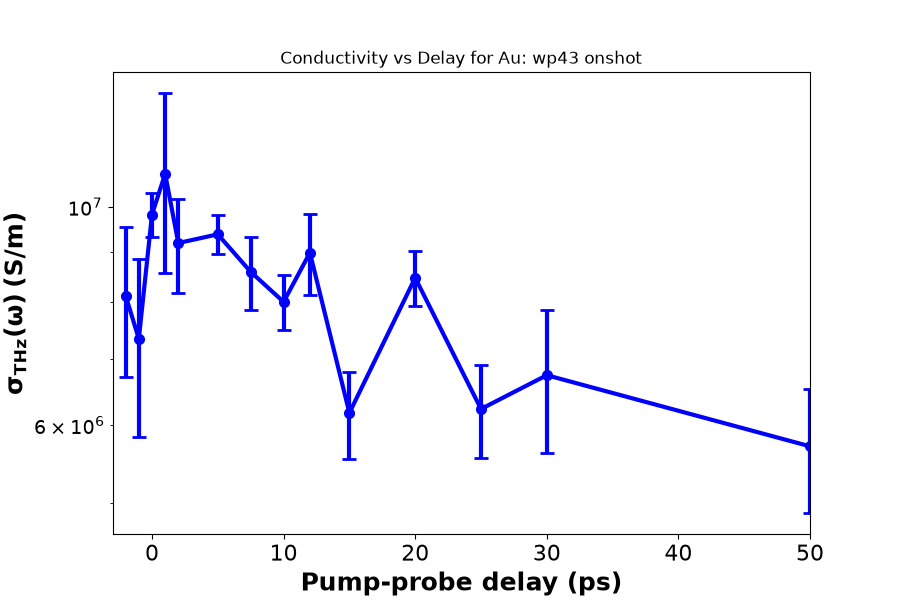

In [ ]:

import matplotlib.pyplot as plt
import numpy.fft as fft
import numpy as np
import os
from pprint import pprint
from myfuncs.utility import saveDict
%matplotlib widget

plt.close('all')

def renameKeys(old_data): # rename keys to float, then sort by key
    new_data = {}
    for key, value in old_data.items():
        if key.startswith('neg'):
            key = key.replace('neg', '-')
            new_key = float(key)
        elif key.startswith('pos'):
            key = key.replace('pos', '')
            if 'p' in key:
                key = key.replace('p', '.')

            new_key = float(key)
        else:
            new_key = key
        new_data[new_key] = value
    sort_data = dict(sorted(new_data.items()))
    return sort_data

file_root = '/Users/yuewang/SLAC/goldthz/Au_data/800nm/processed_data/single_shot/'

wp = 'wp43'
pos = 'pos10'

# sigma vars
Z0 = 376.73
nSi3N4 = 2.7

sigmaData = {} # for storing mean sigmas at each pos

positions = ['neg0', 'neg1', 'neg2', 'pos1', 'pos2', 'pos5', 'pos7p5', 'pos10', 'pos12', 'pos15', 'pos20', 'pos25', 'pos30', 'pos50']
for pos in positions:
    plt.figure()
    plt.title(f"Conductivity vs Frequency for Au: {wp} {pos}")
    plt.xlabel("Frequency (THz)")
    plt.ylabel(r"$\sigma_{THz}(\omega)\:(S/m)$")
    plt.xlim(0, 6)
    realSigmas = [] # for calculating means across shots for each pos

    for shot in range(7):
        if not os.path.exists(file_root + f'SS_Au800_{wp}_{pos}_shot_{shot:04d}/'):
            continue

        file_path = file_root + f'SS_Au800_{wp}_{pos}_shot_{shot:04d}/'
        # load data
        post_bal_raw = np.loadtxt(file_path + 'THz_post_bal.dat')
        post_bal = np.mean(post_bal_raw, axis=1)  # average over the columns
        shot_bal = np.loadtxt(file_path + 'THz_shot_bal.dat')
        time_axis = np.loadtxt(file_path + 'time_axis.dat')

        # compute frequency axis 
        dt = time_axis[1] - time_axis[0]
        N = len(time_axis)

        # zero padding
        Nfft = 5336 # 8 times number of data points

        # padded fft
        ref_fft = fft.fft(post_bal, n=Nfft)
        sig_fft = fft.fft(shot_bal, n=Nfft)
        trans_fft = sig_fft / ref_fft

        freq = fft.fftfreq(Nfft, dt)
        # sort by frequency
        index = np.argsort(freq)
        frq_sort = freq[index]
        ref_sort = ref_fft[index]
        sig_sort = sig_fft[index]

        # finding the mean sigma in a freq range per shot
        sThickness = 30e-9
        transfer = sig_sort/ref_sort
        sigma = ((1 + nSi3N4) / (Z0*sThickness)) * ((1/transfer) - 1)
        sigmaReal = np.real(sigma)
        sigmaSection = np.mean(sigma[(frq_sort >= 0.73) & (frq_sort <= 0.9)])
        realSigmas.append(np.real(sigmaSection))


        plt.plot(frq_sort, sigmaReal, label=f"shot: {shot}")
        plt.legend()

    print(f"sigma values at {pos}: {realSigmas}")
    plt.close()
        
    realSigmaMean = np.mean(realSigmas) # realSigmas holds the mean sigma for each shot at a delay
    realSigmaStd = np.std(realSigmas)
    sigmaData[pos] = {"mean": realSigmaMean, "std": realSigmaStd}
sortedSigmaData = renameKeys(sigmaData)

saveDict(sortedSigmaData, '/Users/yuewang/SLAC/goldthz/Au_data/code/' + 'FFT method/' + '800_nm_FFT_full.json')

print("sorted procesed conductivities")
pprint(sortedSigmaData)
# conductivity vs delay figure 
plt.figure(figsize=(9,6))
yErr = [v["std"] for v in sortedSigmaData.values()]
plt.errorbar(list(sortedSigmaData.keys()), [v["mean"] for v in sortedSigmaData.values()], fmt="-ob", yerr=yErr, capsize=5, capthick=2, ms=7, label="Conductivity", lw=3)
plt.title(f"Conductivity vs Delay for Au: {wp} onshot")
plt.xlabel("Pump-probe delay (ps)", fontsize=18, weight='bold')
plt.ylabel(r"$\mathbf{\sigma_{THz}(\omega)\:(S/m)}$", fontsize=18)
plt.xlim(-3, 50)
plt.yticks(fontsize=16)
plt.tick_params(which="both", axis="both", labelsize=14)

plt.xticks(fontsize=16)
plt.yscale('log')
plt.show()

# Pre-shot conductivities 800 nm
These should be close to unheated conductivity

<>:45: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:45: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/rf/s1m2r2bn7nx64szrkz747pb40000gn/T/ipykernel_66443/3540286761.py:45: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.ylabel(r"$\sigma_{THz}(\omega)\:(S/m)$")


sigma values at neg0: [np.float64(9961479.532213371), np.float64(6023223.795912081), np.float64(6508845.093058966)]
sigma values at neg1: [np.float64(4670194.22855911), np.float64(5906067.890096772), np.float64(7956489.384990273)]
sigma values at neg2: [np.float64(5626072.446954278), np.float64(7633769.745087687), np.float64(6493036.47565941)]
sigma values at pos1: [np.float64(7417338.382609535), np.float64(8642534.616208544), np.float64(8024242.491684883)]
sigma values at pos2: [np.float64(6260281.999872062), np.float64(7709005.482256809), np.float64(5982653.279985752)]
sigma values at pos5: [np.float64(8119840.066384364), np.float64(7273252.884470047), np.float64(7970892.665408904)]
sigma values at pos7p5: [np.float64(6231251.349349633), np.float64(7752064.6515866695), np.float64(6336153.117823206)]
sigma values at pos10: [np.float64(7543142.831938198), np.float64(6108151.051780311), np.float64(6178858.507730549)]
sigma values at pos12: [np.float64(6541645.622137528), np.float64(6459

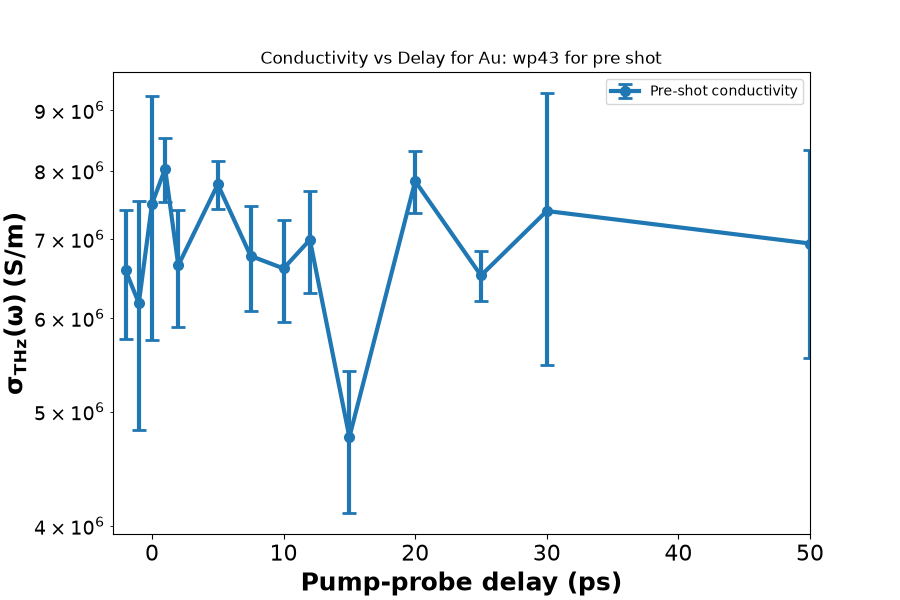

In [ ]:
for pos in positions:
    plt.figure()
    plt.title(f"Conductivity vs Frequency for Au: {wp} {pos} {shot:04d}")
    plt.xlabel("Frequency (THz)")
    plt.ylabel(r"$\sigma_{THz}(\omega)\:(S/m)$")
    plt.xlim(0, 6)
    realSigmas = [] # for calculating means across shots for each pos

    for shot in range(7):
        if not os.path.exists(file_root + f'SS_Au800_{wp}_{pos}_shot_{shot:04d}/'):
            continue

        file_path = file_root + f'SS_Au800_{wp}_{pos}_shot_{shot:04d}/'
        # load data -- pre shot
        post_bal_raw = np.loadtxt(file_path + 'THz_post_bal.dat')
        post_bal = np.mean(post_bal_raw, axis=1)  # average over the columns
        pre_bal_raw = np.loadtxt(file_path + 'THz_pre_bal.dat')
        pre_bal = np.mean(pre_bal_raw, axis=1)
        time_axis = np.loadtxt(file_path + 'time_axis.dat')

        # compute frequency axis 
        dt = time_axis[1] - time_axis[0]
        N = len(time_axis)

        # zero padding
        Nfft = 5336 # 8 times number of data points

        # padded fft
        ref_fft = fft.fft(post_bal, n=Nfft)
        sig_fft = fft.fft(pre_bal, n=Nfft)
        trans_fft = sig_fft / ref_fft

        freq = fft.fftfreq(Nfft, dt)
        # sort by frequency
        index = np.argsort(freq)
        frq_sort = freq[index]
        ref_sort = ref_fft[index]
        sig_sort = sig_fft[index]
        plt.figure()
        plt.plot(frq_sort, np.abs(ref_sort), "-b", label="post-shot")
        plt.plot(frq_sort, np.abs(sig_sort), "-r", label="on-shot")
        plt.title(f"post vs on-shot for Au: {wp} {pos} {shot:04d}")
        plt.xlabel("Frequency (THz)")
        plt.ylabel(r"$\sigma_{THz}(\omega)\:(S/m)$")
        plt.xlim(0, 6)

        # finding the mean sigma in a freq range per shot
        sThickness = 30e-9
        transfer = sig_sort/ref_sort
        sigma = ((1 + nSi3N4) / (Z0*sThickness)) * ((1/transfer) - 1)
        sigmaReal = np.real(sigma)
        sigmaSection = np.mean(sigma[(frq_sort >= 0.73) & (frq_sort <= 0.9)])
        realSigmas.append(np.real(sigmaSection))


        plt.plot(frq_sort, sigmaReal, label=f"shot: {shot}")
        plt.legend()

        if not os.path.exists(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}'):
            os.makedirs(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}')

        if not os.path.exists(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}/sigma_shot_{shot:04d}.png'):
            plt.savefig(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}/sigma_shot_{shot:04d}.png', dpi=300)
    print(f"sigma values at {pos}: {realSigmas}")
    plt.close()
        
    realSigmaMean = np.mean(realSigmas) # realSigmas holds the mean sigma for each shot at a delay
    realSigmaStd = np.std(realSigmas)
    sigmaData[pos] = {"mean": realSigmaMean, "std": realSigmaStd}
sortedSigmaData = renameKeys(sigmaData)
print("sorted procesed conductivities")
pprint(sortedSigmaData)
# conductivity vs delay figure 
plt.figure(figsize=(9,6))
yErr = [v["std"] for v in sortedSigmaData.values()]
plt.errorbar(list(sortedSigmaData.keys()), [v["mean"] for v in sortedSigmaData.values()], fmt="-o", yerr=yErr, capsize=5, capthick=2, ms=7, label="Pre-shot conductivity", lw=3)
plt.title(f"Conductivity vs Delay for Au: {wp} for pre shot")
plt.xlabel("Pump-probe delay (ps)", fontsize=18, weight='bold')
plt.ylabel(r"$\mathbf{\sigma_{THz}(\omega)\:(S/m)}$", fontsize=18)
plt.xlim(-3, 50)
plt.yticks(fontsize=16)
plt.tick_params(which="both", axis="both", labelsize=14)
plt.legend()
plt.xticks(fontsize=16)
plt.yscale('log')
plt.show()

# FFT conductivities of decay (after 5 ps) THz

sigma values at neg0: [np.float64(12875365.23397025), np.float64(10384126.938473992), np.float64(11803743.37497726)]
sigma values at neg1: [np.float64(7410406.798474936), np.float64(6927799.218588215), np.float64(9770893.39088044)]
sigma values at neg2: [np.float64(10725583.071928121), np.float64(16420249.980706077), np.float64(12033579.145768091)]
sigma values at pos1: [np.float64(13762475.901514027), np.float64(13022017.825941801), np.float64(12846312.808018047)]
sigma values at pos2: [np.float64(9595569.26812569), np.float64(12471141.16373358), np.float64(9580707.785362996)]
sigma values at pos5: [np.float64(10648108.792333836), np.float64(10354911.12138017), np.float64(11195543.883366821)]
sigma values at pos7p5: [np.float64(9359185.56333414), np.float64(11156665.659224663), np.float64(9065697.33101469)]
sigma values at pos10: [np.float64(8309485.368163656), np.float64(8162761.651975248), np.float64(8551108.374186125)]
sigma values at pos12: [np.float64(8785016.316062108), np.float

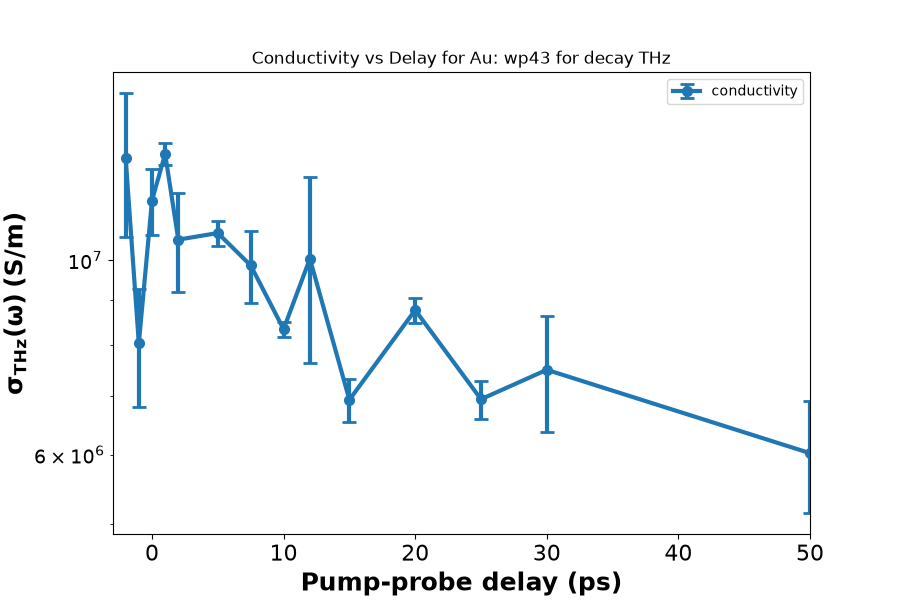

In [ ]:
for pos in positions:
    plt.figure()
    plt.title(f"Conductivity vs Frequency for Au: {wp} {pos}")
    plt.xlabel("Frequency (THz)")
    plt.ylabel(r"$\sigma_{THz}(\omega)\:(S/m)$")
    plt.xlim(0, 6)
    realSigmas = [] # for calculating means across shots for each pos

    for shot in range(7):
        if not os.path.exists(file_root + f'SS_Au800_{wp}_{pos}_shot_{shot:04d}/'):
            continue

        file_path = file_root + f'SS_Au800_{wp}_{pos}_shot_{shot:04d}/'
        try:
            # load data -- pre shot
            post_bal = np.loadtxt(file_path + 'dec_post.dat')
            shot_bal = np.loadtxt(file_path + 'dec_shot.dat')
            time_axis = np.loadtxt(file_path + 'dec_time.dat')
        except FileNotFoundError as e:
            print(f"File not found: {e}")
            continue

        # compute frequency axis 
        dt = time_axis[1] - time_axis[0]
        N = len(time_axis)

        # zero padding
        Nfft = 5336 # 8 times number of data points

        # padded fft
        ref_fft = fft.fft(post_bal, n=Nfft)
        sig_fft = fft.fft(shot_bal, n=Nfft)
        trans_fft = sig_fft / ref_fft

        freq = fft.fftfreq(Nfft, dt)
        # sort by frequency
        index = np.argsort(freq)
        frq_sort = freq[index]
        ref_sort = ref_fft[index]
        sig_sort = sig_fft[index]

        # finding the mean sigma in a freq range per shot
        sThickness = 30e-9
        transfer = sig_sort/ref_sort
        sigma = ((1 + nSi3N4) / (Z0*sThickness)) * ((1/transfer) - 1)
        sigmaReal = np.real(sigma)
        sigmaSection = np.mean(sigma[(frq_sort >= 0.73) & (frq_sort <= 0.9)])
        realSigmas.append(np.real(sigmaSection))


        plt.plot(frq_sort, sigmaReal, label=f"shot: {shot}")
        plt.legend()

        if not os.path.exists(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}'):
            os.makedirs(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}')

        if not os.path.exists(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}/sigma_shot_{shot:04d}.png'):
            plt.savefig(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}/sigma_shot_{shot:04d}.png', dpi=300)
    print(f"sigma values at {pos}: {realSigmas}")
    plt.close()
        
    realSigmaMean = np.mean(realSigmas) # realSigmas holds the mean sigma for each shot at a delay
    realSigmaStd = np.std(realSigmas)
    sigmaData[pos] = {"mean": realSigmaMean, "std": realSigmaStd}
sortedSigmaData = renameKeys(sigmaData)

saveDict(sortedSigmaData, '/Users/yuewang/SLAC/goldthz/Au_data/code/' + 'FFT method/' + '800_nm_FFT_5ps.json')
    
print("sorted procesed conductivities")
pprint(sortedSigmaData)
# conductivity vs delay figure 
plt.figure(figsize=(9,6))
yErr = [v["std"] for v in sortedSigmaData.values()]
plt.errorbar(list(sortedSigmaData.keys()), [v["mean"] for v in sortedSigmaData.values()], fmt="-o", yerr=yErr, capsize=5, capthick=2, ms=7, label="conductivity", lw=3)
plt.title(f"Conductivity vs Delay for Au: {wp} for decay THz")
plt.xlabel("Pump-probe delay (ps)", fontsize=18, weight='bold')
plt.ylabel(r"$\mathbf{\sigma_{THz}(\omega)\:(S/m)}$", fontsize=18)
plt.xlim(-3, 50)
plt.yticks(fontsize=16)
plt.tick_params(which="both", axis="both", labelsize=14)
plt.legend()
plt.xticks(fontsize=16)
plt.yscale('log')

## This is removing thz after 4 ps 
Adds a exponential decay to 0 after 4ps to get rid of noise

sigma values at neg0: [np.float64(14580466.039623845), np.float64(12015531.997937378), np.float64(14125067.468647838)]
sigma values at neg1: [np.float64(14876871.367929444), np.float64(19593872.626368556), np.float64(21442019.3635645)]
sigma values at neg2: [np.float64(16597382.14804041), np.float64(25687416.4209216), np.float64(20204094.356690466)]
sigma values at pos1: [np.float64(12964198.582659686), np.float64(12578830.182733623), np.float64(12909085.512870014)]
sigma values at pos2: [np.float64(10169895.8411052), np.float64(12929301.267421123), np.float64(9925077.008184899)]
sigma values at pos5: [np.float64(11156121.705709392), np.float64(10471714.500912946), np.float64(11182920.739469621)]
sigma values at pos7p5: [np.float64(9469638.463499354), np.float64(11565937.666017916), np.float64(8928983.544010568)]
sigma values at pos10: [np.float64(8404294.58696186), np.float64(8452060.563033028), np.float64(8901540.37648913)]
sigma values at pos12: [np.float64(8783402.716204047), np.fl

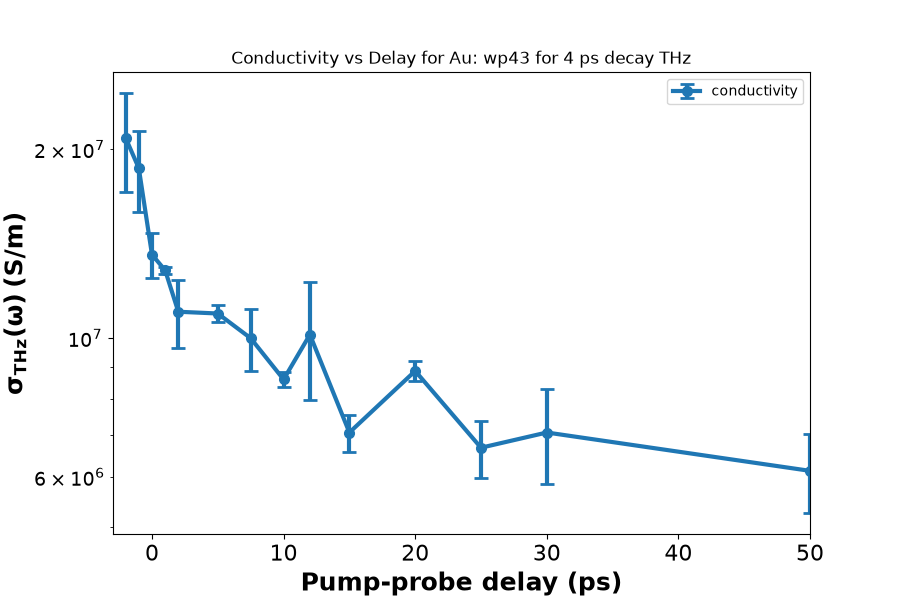

In [16]:
for pos in positions:
    plt.figure()
    plt.title(f"Conductivity vs Frequency for Au: {wp} {pos} {shot:04d}")
    plt.xlabel("Frequency (THz)")
    plt.ylabel(r"$\sigma_{THz}(\omega)\:(S/m)$")
    plt.xlim(0, 6)
    realSigmas = [] # for calculating means across shots for each pos

    for shot in range(7):
        if not os.path.exists(file_root + f'SS_Au800_{wp}_{pos}_shot_{shot:04d}/'):
            continue

        file_path = file_root + f'SS_Au800_{wp}_{pos}_shot_{shot:04d}/'
        try:
            # load data -- pre shot
            post_bal = np.loadtxt(file_path + 'dec_post_4ps.dat')
            shot_bal = np.loadtxt(file_path + 'dec_shot_4ps.dat')
            time_axis = np.loadtxt(file_path + 'dec_time_4ps.dat')
        except FileNotFoundError as e:
            print(f"File not found: {e}")
            continue

        # compute frequency axis 
        dt = time_axis[1] - time_axis[0]
        N = len(time_axis)

        # zero padding
        Nfft = 5336 # 8 times number of data points

        # padded fft
        ref_fft = fft.fft(post_bal, n=Nfft)
        sig_fft = fft.fft(shot_bal, n=Nfft)
        trans_fft = sig_fft / ref_fft

        freq = fft.fftfreq(Nfft, dt)
        # sort by frequency
        index = np.argsort(freq)
        frq_sort = freq[index]
        ref_sort = ref_fft[index]
        sig_sort = sig_fft[index]

        # finding the mean sigma in a freq range per shot
        sThickness = 30e-9
        transfer = sig_sort/ref_sort
        sigma = ((1 + nSi3N4) / (Z0*sThickness)) * ((1/transfer) - 1)
        sigmaReal = np.real(sigma)
        sigmaSection = np.mean(sigma[(frq_sort >= 0.73) & (frq_sort <= 0.9)])
        realSigmas.append(np.real(sigmaSection))


        plt.plot(frq_sort, sigmaReal, label=f"shot: {shot}")
        plt.legend()

        """
        if not os.path.exists(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}'):
            os.makedirs(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}')

        if not os.path.exists(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}/sigma_shot_{shot:04d}.png'):
            plt.savefig(file_root + '/conductivity plots/' + f'SS_Au800_{wp}_{pos}/sigma_shot_{shot:04d}.png', dpi=300)
        """
    print(f"sigma values at {pos}: {realSigmas}")
    plt.close()
        
    realSigmaMean = np.mean(realSigmas) # realSigmas holds the mean sigma for each shot at a delay
    realSigmaStd = np.std(realSigmas)
    sigmaData[pos] = {"mean": realSigmaMean, "std": realSigmaStd}
sortedSigmaData = renameKeys(sigmaData)

saveDict(sortedSigmaData, '/Users/yuewang/SLAC/goldthz/Au_data/code/' + 'FFT method/' + '800_nm_FFT_4ps.json')

print("sorted procesed conductivities")
pprint(sortedSigmaData)
# conductivity vs delay figure 
plt.figure(figsize=(9,6))
yErr = [v["std"] for v in sortedSigmaData.values()]
plt.errorbar(list(sortedSigmaData.keys()), [v["mean"] for v in sortedSigmaData.values()], fmt="-o", yerr=yErr, capsize=5, capthick=2, ms=7, label="conductivity", lw=3)
plt.title(f"Conductivity vs Delay for Au: {wp} for 4 ps decay THz")
plt.xlabel("Pump-probe delay (ps)", fontsize=18, weight='bold')
plt.ylabel(r"$\mathbf{\sigma_{THz}(\omega)\:(S/m)}$", fontsize=18)
plt.xlim(-3, 50)
plt.yticks(fontsize=16)
plt.tick_params(which="both", axis="both", labelsize=14)
plt.legend()
plt.xticks(fontsize=16)
plt.yscale('log')

